# Tutorial: Cruise Control with dynamicalnodes

```{admonition} Download
:class: tip
{download}`Download this notebook <cruise_control_with_dynamicalnodes.ipynb>`
```

## Overview

This is a tutorial notebook for the `dynamicalnodes` package. It walks the user through the basic theory behind the package and several usage examples. This notebook is entirely self-contained: we start from installation and end with a live ROS graph of a feedback system

The purpose of the `dynamicalnodes` package is to help the user rapidly iterate on control/estimation algorithms within the ROS framework.

The package architecture is simple. There are only two classes and three methods:

```
dynamicalnodes
├── DynamicalSystem                # class
│   └── .step()                    # method
├── ROSNode                        # class
│   ├── .step()                    # method
│   └── .write_ROSNode_to_rclpy()  # method
└── ros2py_py2ros                  # accessory module
```

Depending on your background, the theory behind the package is also simple. The notebook should explain the relevant parts of the theory as needed, although it couldn't hurt to have a copy of the paper at hand (e.g. most of the examples in this notebook are pulled directly from the paper).

```{admonition} Using an AI coding assistant
:class: tip
The repository ships five [Claude Code skills](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills) that walk an assistant (or you) through the same steps as this notebook. Boxes labeled **Skill** mark the places where one is useful: [`discretize-f-h`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/discretize-f-h), [`simulate-with-dynamicalsystem`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/simulate-with-dynamicalsystem), [`wrap-in-rosnode`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/wrap-in-rosnode), [`write-ros-converters`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/write-ros-converters), [`deploy-rosnodes-to-rclpy`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/deploy-rosnodes-to-rclpy). Clone the repository to use them (see the README); they are not part of the `pip` package.
```

The notebook is structured around the `dynamicalnodes` classes, in reading order. The `ROSNode` class has
ROS dependencies while `DynamicalSystem` does not, which is why the installation instructions are separate.

**`DynamicalSystem`**
- [Installation (base)](#installation-base)
- [Dynamical Systems (II-A)](#dynamical-systems-ii-a)
  - [Continuous-Time Dynamical Systems (CTDS)](#continuous-time-dynamical-systems-ctds)
  - [Discrete-time Dynamical Systems (DTDS)](#discrete-time-dynamical-systems-dtds)
- [The `DynamicalSystem` Class (III-B)](#the-dynamicalsystem-class-iii-b)
  - [`DynamicalSystem.step()`](#dynamicalsystemstep)
  - [Composing Dynamical Systems](#composing-dynamical-systems)

  - [Example: Car with Speedometer (II-A1)](#example-car-with-speedometer-ii-a1)
  - [Example: Signal Generators (II-A2)](#example-signal-generators-ii-a2)
  - [Example: Composing Dynamical Systems (II-A3)](#example-composing-dynamical-systems-ii-a3)
- [Discrete-time Diagrams (II-B)](#discrete-time-diagrams-ii-b)

**`ROSNode`**
- [Installation (ROS)](#installation-ros)
- [The Robot Operating System (II-C)](#the-robot-operating-system-ii-c)
- [Overview of Workflow (III-A)](#overview-of-workflow-iii-a)
- [The `ROSNode` Class (III-C)](#the-rosnode-class-iii-c)
  - [Testing Data Translation](#testing-data-translation)
  - [Generating `rclpy` files](#generating-rclpy-files)
  - [Sim Time to Node Time](#sim-time-to-node-time)

**A final example demonstrating the entire workflow**
- [Example: Car Cruise Control (IV)](#example-car-cruise-control-iv)
  - [Linear Longitudinal Vehicle with Measurements (IV-A)](#linear-longitudinal-vehicle-with-measurements-iv-a)
  - [Sinusoidal Reference Generator (IV-B)](#sinusoidal-reference-generator-iv-b)
  - [PID Controller (IV-C)](#pid-controller-iv-c)
  - [Linear Kalman Filter (IV-D)](#linear-kalman-filter-iv-d)
  - [Simulating the Discrete-Time Diagram](#simulating-the-discrete-time-diagram)
  - [Generating the ROS Graph (IV-E)](#generating-the-ros-graph-iv-e)
    - [Wrapping the Blocks and Verifying the Converters](#wrapping-the-blocks-and-verifying-the-converters)
    - [Deploying to ROS2](#deploying-to-ros2)
    - [The Launch File](#the-launch-file)
    - [Running the Live ROS2 Graph](#running-the-live-ros2-graph)
    - [Tuning PID Gains Live](#tuning-pid-gains-live)
    - [You Don't Need the Launch File](#you-dont-need-the-launch-file)

## Installation (base)

<details>
<summary><b>Click to show the installation instructions for the <code>DynamicalSystem</code> half</b></summary>

To run the [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) half of this notebook, you'll need

- **Python 3.12 or newer.** Check with `python3 --version` in a terminal (you can probably get away with an older version, but I haven't tested that yet.)
- **`dynamicalnodes`** (its only dependency is `numpy`)
- **`matplotlib`, `scipy`, and `jupyter`** (for plots, continuous-time solver, and working with the notebook).

No ROS2 is needed here. The [`ROSNode`](https://nehalsinghmangat.github.io/dynamicalnodes/api/rosnode.html#dynamicalnodes.rosnode.ROSNode) half has its own installation section, [Installation (ROS)](#installation-ros), which you can follow later.

The terminal commands below are for Linux and macOS.

**Pulling from the Repo**

Cloning the repository gets you a local copy of the latest code, this notebook, and the rest of the documentation. It is the best option if you want to read the source or modify the package. You need [git](https://git-scm.com/downloads) installed.

```bash
git clone https://github.com/nehalsinghmangat/dynamicalnodes
cd dynamicalnodes
python3 -m venv .venv # creating the virtual environment
source .venv/bin/activate
pip install -e ".[docs]"
```

```{note}
A *virtual environment* (venv) is a private folder of Python packages for this project, so installing here does not touch the rest of your system. `source .venv/bin/activate` switches your terminal to it; run it again in every new terminal.
```

```{note}
`-e` makes an *editable* install: Python imports the package straight from the cloned folder, so any change you make to the source takes effect immediately. The `[docs]` part also installs `matplotlib`, `scipy`, and `jupyter`, which this notebook uses. If you plan to contribute, use `".[dev,docs]"` to also get the testing and formatting tools. This notebook is in `docs/source/tutorials/0_cruise_control/`.
```

**pip install**

If you just want to use the package, install it from PyPI.

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install dynamicalnodes scipy matplotlib jupyter
```

You can download this notebook with the link at the top of the page and open it from the same folder.

Once installed, start Jupyter **from the activated venv**:

```bash
jupyter lab
```

Then run the check cell below this section to confirm the setup.

</details>

Check your setup from inside the notebook:

In [1]:
# Necessary for DynamicalSystem section

import sys

import matplotlib
import numpy
import scipy

import dynamicalnodes

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)  # should point inside your .venv
print("dynamicalnodes imported from:", dynamicalnodes.__file__)
assert sys.version_info >= (3, 12), "dynamicalnodes needs Python 3.12 or newer"

Python: 3.12.12
Interpreter: /home/nehal/.pyenv/versions/3.12.12/envs/pykal-3.12.12/bin/python
dynamicalnodes imported from: /home/nehal/projectile/nehalsinghmangat/dynamicalnodes/src/dynamicalnodes/__init__.py


## Dynamical Systems (II-A)

A *dynamical system* is a vector field $\dot{x} = f(x, \dots)$, where $x$ is called the *state*. In a controls context, $f$ typically takes a state vector $x$, an input vector $u$, and a parameter vector $\theta$ i.e.

$$\dot{x} = f(x, u, \theta)$$

Often the state is not directly observable, so it is described with a second function $h$, the *measurement* function. Alternatively, if the output of a system is some function of the state, we call $h$ an *output* function. Regardless, the function $h$ accepts the same arguments as $f$ and returns an output vector $y$:

$$y = h(x, u, \theta)$$

### Continuous-Time Dynamical Systems (CTDS)
Taken together, the vector field $f$ (often called the dynamics) and the function $h$ form a *continuous-time dynamical system*:

$$\dot{x} = f(x, u, \theta), \qquad y = h(x, u, \theta).$$

As an example, consider a driven harmonic oscillator with damping. A mass $m$ on a spring of stiffness $k$ with viscous damping $c$ is driven by an external force $u$. Let the state be $x = (d, v)$, the displacement from equilibrium and the velocity, and let the parameters be $\theta = (m, k, c)$. Newton's second law, $m\dot{v} = u - k d - c v$, gives the dynamics function $f$. For measurements, we consider a measurement function $h$ that returns position. The standard state-space representation of this CTDS is then

$$\dot{x} = f(x, u, \theta) = \begin{bmatrix} \dot{d} \\ \dot{v} \end{bmatrix} = \begin{bmatrix} 0 & 1 \\ -\dfrac{k}{m} & -\dfrac{c}{m} \end{bmatrix} \begin{bmatrix} d \\ v \end{bmatrix} + \begin{bmatrix} 0 \\ \dfrac{1}{m} \end{bmatrix} u $$

$$y = h(x, u, \theta) = \begin{bmatrix} 1 & 0 \end{bmatrix} \begin{bmatrix} d \\ v \end{bmatrix} = d.$$

```{admonition} Aside on Theory
:class: tip
 $h$ technically does not need to have $u$ or $\theta$ as arguments, but defining the $f$ and $h$ functions to have the same domain simplifies the mathematics. When we actually implement $f$ and $h$, we do not need to include unused arguments.
```

We implement these functions in Python below:

In [2]:
import numpy as np


def f_cont(
    x: np.ndarray,  # shape=(2,1)
    u: float,
    theta: tuple[float, float, float],
) -> np.ndarray:
    """Continuous-time dynamics: returns xdot = A x + B u."""
    m, k, c = theta
    A = np.array([[0.0, 1.0], [-k / m, -c / m]])
    B = np.array([0.0, 1.0 / m])
    return A @ x + B * u


def h_cont(
    x: np.ndarray,
) -> float:
    """Measurement: y = C x (position only)."""
    C = np.array([[1.0, 0.0]])
    return (C @ x)[0]  # [0] extracts float from (1,1) array

We need a numerical solver to simulate this system over time. We use solve_ivp from scipy.integrate and use the default **RK45** method. Expand the cell to see the code.

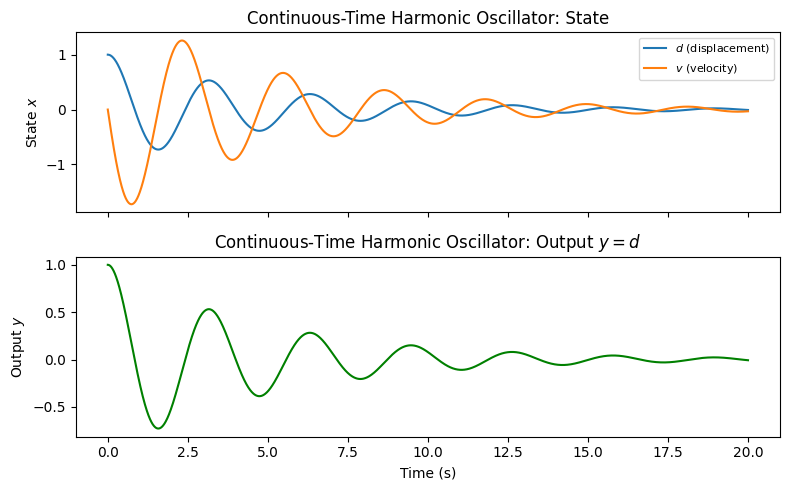

In [3]:
import os

os.makedirs("plots", exist_ok=True)

import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# With $u = 0$ and $c = 0$ the solution oscillates at the natural frequency $\omega_0 = \sqrt{k/m}$; a positive $c$ makes the oscillation decay.
theta = (1.0, 4.0, 0.4)  # m, k, c  ->  omega_0 = 2 rad/s, underdamped
x0 = (1.0, 0.0)  # released from rest at d = 1
t_eval = np.linspace(0.0, 20.0, 2001)

# u = 0 (free response); solve_ivp expects rhs(t, x) -> xdot
sol = solve_ivp(
    lambda t, x: f_cont(x, 0.0, theta), (0.0, 20.0), x0, t_eval=t_eval, method="RK45"
)
y = [h_cont(x) for x in sol.y.T]

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axs[0].plot(sol.t, sol.y[0], label="$d$ (displacement)")
axs[0].plot(sol.t, sol.y[1], label="$v$ (velocity)")
axs[0].set_ylabel("State $x$")
axs[0].set_title("Continuous-Time Harmonic Oscillator: State")
axs[0].legend(fontsize=8)
axs[1].plot(sol.t, y, color="green")
axs[1].set_ylabel("Output $y$")
axs[1].set_xlabel("Time (s)")
axs[1].set_title("Continuous-Time Harmonic Oscillator: Output $y = d$")
plt.tight_layout()
plt.savefig("plots/ct_oscillator.png", dpi=200, bbox_inches="tight")
plt.show()

![State and output of the continuous-time harmonic oscillator, simulated with solve_ivp.](plots/ct_oscillator.png)

### Discrete-time Dynamical Systems (DTDS)
While a discrete-time dynamical system, or DTDS, still has an $f$ and $h$ function, the $f$ function is now discrete; that is,

$$x_{k+1} = f(x_k, u, \theta), \qquad y_k = h(x_k, u_k, \theta).$$

In such a paradigm, $f$ is often referred to as the *evolution* function. Any CTDS can be converted into a DTDS. We demonstrate one method of doing so with the harmonic oscillator example.


**Discretizing the harmonic oscillator.** As the harmonic oscillator in the previous section was linear, we can write the CTDS in matrix form, $\dot{x} = Ax + Bu$, $y = Cx$, with

$$A = \begin{bmatrix} 0 & 1 \\ -\dfrac{k}{m} & -\dfrac{c}{m} \end{bmatrix}, \qquad B = \begin{bmatrix} 0 \\ \dfrac{1}{m} \end{bmatrix}, \qquad C = \begin{bmatrix} 1 & 0 \end{bmatrix}.$$

We then have

$$x_{k+1} = A_d x_k + B_d u_k, \qquad y_k = C x_k,$$

where $A_d$ and $B_d$ are defined as follows for a chosen time step $\Delta t$:

$$A_d = e^{A\Delta t}, \qquad B_d = A^{-1}\left(A_d - I\right)B.$$

where $k \neq 0$ to keep $A$ invertible. Since we discretized a linear system, there is no error.

```{admonition} Aside on Theory
:class: tip

For nonlinear systems there is no such closed form solution. We must rely on integration schemes, the simplest being forward Euler, $x_{k+1} = x_k + \Delta t\, f(x_k, u_k, \theta)$. For this oscillator, forward Euler would give $A_d \approx I + A\Delta t$ and $B_d \approx B\Delta t$.
```

```{admonition} Skill: discretize-f-h
:class: tip
To go from your own continuous-time model to discrete-time `f` and `h` (exact matrix exponential for linear systems, Euler or RK4 for nonlinear ones, validation against `solve_ivp`), use the [`discretize-f-h`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/discretize-f-h) skill.
```

The evolution function $f$ and the measurement function $h$ of the DTDS are implemented in Python below:

In [4]:
from scipy.linalg import expm


def f_dt(
    xk: tuple[float, float],
    uk: float,
    theta: tuple[float, float, float],
    dt: float,
) -> tuple[float, float]:
    """Discrete-time dynamics (exact, zero-order hold): returns x_{k+1}."""
    m, k, c = theta
    A = np.array([[0.0, 1.0], [-k / m, -c / m]])
    B = np.array([0.0, 1.0 / m])
    Ad = expm(A * dt)
    Bd = np.linalg.solve(A, (Ad - np.eye(2)) @ B)
    x_next = Ad @ np.array(xk) + Bd * uk
    return (x_next[0], x_next[1])


def h_dt(  # this is unchanged from h_cont
    xk: tuple[float, float],
) -> float:
    """Measurement: y_k = C x_k (position only)."""
    C = np.array([[1.0, 0.0]])
    return (C @ np.array(xk))[0]

**Simulating the DTDS.** Since a DTDS is discrete, we can simulate it directly in a for loop. There is no need for a solver.

```{admonition} Skill: simulate-with-dynamicalsystem
:class: tip
For the loop template (call order, initial states and feedback inputs, history, composing blocks) and a checklist of common mistakes, use the [`simulate-with-dynamicalsystem`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/simulate-with-dynamicalsystem) skill.
```

In [5]:
dt = 0.1
n_steps = int(20.0 / dt)
t_sim = np.arange(n_steps + 1) * dt  # simulation times t_k = k * dt

xk = x0  # same initial state as the continuous-time simulation
xk_hist, yk_hist = [], []
for tk in t_sim:
    uk = 0.0  # free response, no input
    yk = h_dt(xk)  # y_k from the current state x_k
    xk_hist.append(xk)
    yk_hist.append(yk)
    xk_next = f_dt(xk, uk, theta, dt)  # advance to x_{k+1}
    xk = xk_next

xk_hist = np.array(xk_hist)

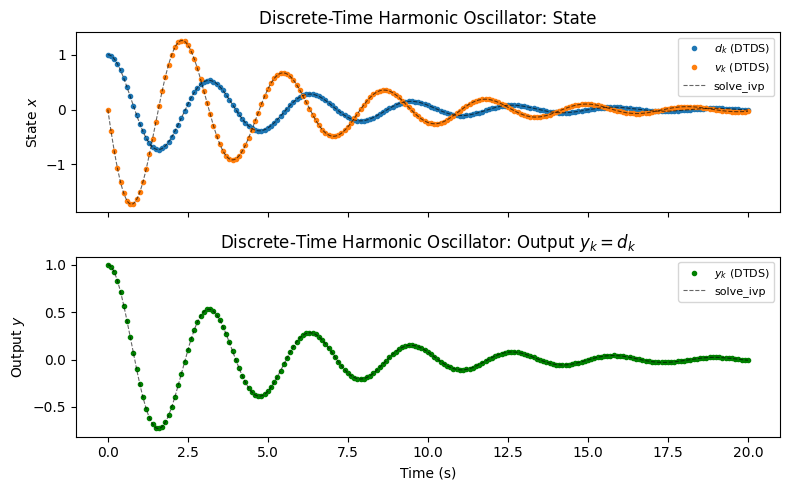

In [6]:
import os

os.makedirs("plots", exist_ok=True)

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axs[0].plot(t_sim, xk_hist[:, 0], "o", ms=3, label="$d_k$ (DTDS)")
axs[0].plot(t_sim, xk_hist[:, 1], "o", ms=3, label="$v_k$ (DTDS)")
axs[0].plot(sol.t, sol.y[0], "k--", lw=0.8, alpha=0.6, label="solve_ivp")
axs[0].plot(sol.t, sol.y[1], "k--", lw=0.8, alpha=0.6)
axs[0].set_ylabel("State $x$")
axs[0].set_title("Discrete-Time Harmonic Oscillator: State")
axs[0].legend(fontsize=8)
axs[1].plot(t_sim, yk_hist, "o", ms=3, color="green", label="$y_k$ (DTDS)")
axs[1].plot(
    sol.t,
    [h_cont(x) for x in sol.y.T],
    "k--",
    lw=0.8,
    alpha=0.6,
    label="solve_ivp",
)
axs[1].set_ylabel("Output $y$")
axs[1].set_xlabel("Time (s)")
axs[1].set_title("Discrete-Time Harmonic Oscillator: Output $y_k = d_k$")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("plots/dt_oscillator.png", dpi=200, bbox_inches="tight")
plt.show()

![State and output of the discrete-time harmonic oscillator, overlaid on the solve_ivp solution.](plots/dt_oscillator.png)

The simplicity of simulating discrete-time systems is the reason for the DTDS-based approach to modeling and system composition used in `dynamicalnodes`, as we shall see in the next section.

## The `DynamicalSystem` Class (III-B)

The [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) class takes an evolution function $f(x_k,...) \to x_{k+1}$ and an output function $h(x_k,...) \to y_k$ and encapsulates them into a `DynamicalSystem` object.

See the [`DynamicalSystem` API reference](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) for the full documentation of the class.

In [7]:
import dynamicalnodes as dn


def f_dt(
    xk: tuple[float, float],
    uk: float,
    theta: tuple[float, float, float],
    dt: float,
) -> tuple[float, float]:
    """Discrete-time dynamics (exact, zero-order hold): returns x_{k+1}."""
    m, k, c = theta
    A = np.array([[0.0, 1.0], [-k / m, -c / m]])
    B = np.array([0.0, 1.0 / m])
    Ad = expm(A * dt)
    Bd = np.linalg.solve(A, (Ad - np.eye(2)) @ B)
    x_next = Ad @ np.array(xk) + Bd * uk
    return (x_next[0], x_next[1])


def h_dt(  # this is unchanged from h_cont
    xk: tuple[float, float],
) -> float:
    """Measurement: y_k = C x_k (position only)."""
    C = np.array([[1.0, 0.0]])
    return (C @ np.array(xk))[0]


driven_damped_harmonic_oscillator = dn.DynamicalSystem(f=f_dt, h=h_dt)
print(driven_damped_harmonic_oscillator)  # (f_dt,h_dt)

(f_dt, h_dt)


### `DynamicalSystem.step()`

Recall that simulating the discrete harmonic oscillator, while simpler than the continuous version, was still somewhat unwieldy:

In [8]:
dt = 0.1
n_steps = int(20.0 / dt)
t_sim = np.arange(n_steps + 1) * dt

xk = x0
xk_hist, yk_hist = [], []
for tk in t_sim:
    uk = 0.0  # free response, no input
    yk = h_dt(xk)  # y_k from the current state x_k
    xk_hist.append(xk)
    yk_hist.append(yk)
    xk_next = f_dt(xk, uk, theta, dt)  # advance to x_{k+1}
    xk = xk_next
xk_hist = np.array(xk_hist)

The [`DynamicalSystem.step()`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem.step) method acts as syntactic sugar to simplify calling the bound `f` and `h` functions. `.step()` accepts *all* parameters for `f` and `h` as a pool of keyword arguments and then passes those keyword arguments to matching args/kwargs in the functions signature. This way, we do not have to repeat shared parameters.

Either `f` or `h` may be left out of the constructor. `step` then returns `None` in that slot of its `(x_next, y)` result, and if both are omitted it raises a `ValueError`. See the [`DynamicalSystem.step` API reference](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem.step) for the full list of cases.

In [9]:
dt = 0.1
n_steps = int(20.0 / dt)
t_sim = np.arange(n_steps + 1) * dt

xk = x0
xk_hist, yk_hist = [], []
for tk in t_sim:
    uk = 0.0  # free response, no input
    xk_next, yk = driven_damped_harmonic_oscillator.step(
        xk=xk, uk=uk, theta=theta, dt=dt
    )
    xk_hist.append(xk)
    yk_hist.append(yk)
    xk = xk_next
xk_hist = np.array(xk_hist)

![State and output of the harmonic oscillator simulated with DynamicalSystem.step(), overlaid on the solve_ivp solution; it is the same trajectory as the raw for-loop.](plots/dt_oscillator_step.png)

### Composing Dynamical Systems
Because a [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) is just a pair of functions behind one interface, building bigger systems is a matter of feeding the output of one into the input of another. So far we have set $u_k = 0$ for the input of our harmonic oscillator. Instead, let a second system generate the input.

A sinusoidal signal generator is the stateless system (i.e. no dynamics function $f$, so the tuple is (*,$h$)) given by $(*, h_{\mathrm{drive}})$ with parameters $(A, \omega)$:

$$u_k = h_{\mathrm{drive}}(t_k, A, \omega) = A \sin(\omega t_k).$$

Composing the driver with the oscillator means calling the generator first and passing its output to the oscillator's `uk`.

In [10]:
def hdrive(tk: float, A: float = 1.0, omega: float = 2.0) -> float:
    return A * np.sin(omega * tk)


driver = dn.DynamicalSystem(h=hdrive)  # (*, hdrive)
print(driver)

# composition: drive -> driven_damped_harmonic_oscillator
xk = x0
x_res, u_res = [], []
for tk in t_sim:
    _, uk = driver.step(tk=tk, A=1.0, omega=2.0)
    xk_next, yk = driven_damped_harmonic_oscillator.step(
        xk=xk, uk=uk, theta=theta, dt=dt
    )
    x_res.append(xk)
    u_res.append(uk)
    xk = xk_next

(*, hdrive)


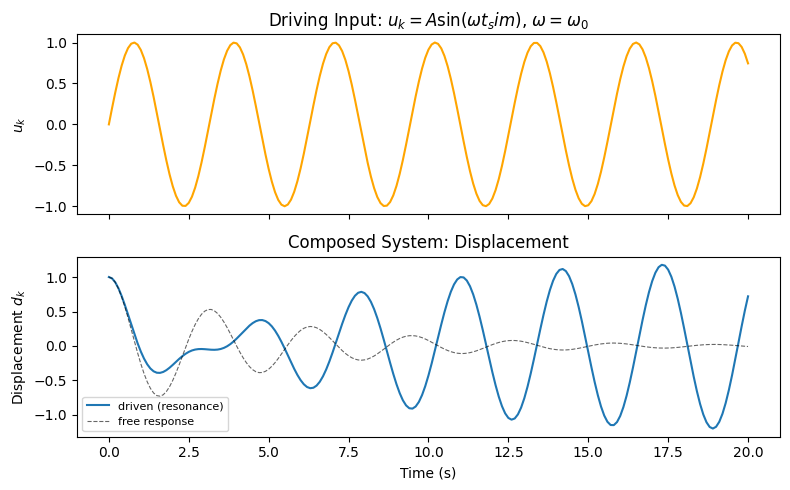

In [11]:
import os

os.makedirs("plots", exist_ok=True)

x_res = np.array(x_res)

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axs[0].plot(t_sim, u_res, color="orange")
axs[0].set_ylabel("$u_k$")
axs[0].set_title("Driving Input: $u_k = A\\sin(\\omega t_sim)$, $\\omega = \\omega_0$")
axs[1].plot(t_sim, x_res[:, 0], label="driven (resonance)")
axs[1].plot(t_sim, xk_hist[:, 0], "k--", lw=0.8, alpha=0.6, label="free response")
axs[1].set_ylabel("Displacement $d_k$")
axs[1].set_xlabel("Time (s)")
axs[1].set_title("Composed System: Displacement")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("plots/oscillator_resonance.png", dpi=200, bbox_inches="tight")
plt.show()

![Driving input and displacement of the oscillator driven at resonance, compared with its free response.](plots/oscillator_resonance.png)

```{admonition} Flexibility of f and h
:class: tip
Function signatures are unconstrained in name, type, and number of parameters. All that matters is consistency between the input/output type of the dynamics function `f` (i.e. `xk` and `xk_next` better be the same type) and consistency between composed dynamical systems (e.g. `h` better return a `float` if the next dynamical system in the chain expects an input of type `float`)
```

```{admonition} The reserved argument name tk
:class: tip
Declaring time is optional. If `f` or `h` has a parameter named exactly `tk`, a generated `ROSNode` fills it with the seconds elapsed since the node started (see [Sim Time to Node Time](#sim-time-to-node-time)).
```

We now go through the examples in the paper.


### Example: Car with Speedometer (II-A1)

Suppose we wish to model a car with speed measurements. We choose an evolution function $f_{car}$ describing the motion of the car and a measurement function $h_{sp}$ extracting speed from the car's state. To build $(f_{car}, h_{sp})$ we construct $(f_{car}, *)$ and $(*, h_{sp})$ separately first.

**Car dynamics** $(f_{car}, *)$. Let the state be $x_k = (d_k, v_k)$, displacement and velocity. Let the control input be $u_k$ and the parameters $\theta_{car} = (m, b, \Delta t)$: mass, aerodynamic drag, and time step.

$$(f_{car}, *)(x_k, u_k, \theta_{car}) = \left(\begin{bmatrix} d_k + \Delta t\, v_k \\ v_k + \Delta t\left(\dfrac{u_k - b v_k}{m}\right) \end{bmatrix},\, *\right)$$


In [12]:
def fcar(
    xk: tuple[float, float], uk: float, theta_car: tuple[float, float, float]
) -> tuple[float, float]:
    dk, vk = xk
    m, b, dt = theta_car
    return (dk + dt * vk, vk + dt * (uk - b * vk) / m)


**Speedometer** $(*, h_{sp})$. The speed measurement has additive zero-mean Gaussian noise with standard deviation $\sigma$, so $\theta_{sp} = (\sigma,)$:

$$(*, h_{sp})(x_k, u_k, \theta_{sp}) = (*,\, |v_k| + q_k), \qquad q_k \sim \mathcal{N}(0, \sigma^2)$$


In [13]:
def hcar(xk: tuple[float, float], sigma: float = 0.5) -> float:
    _, vk = xk
    return np.abs(vk) + np.random.normal(0.0, sigma)


**Car with speedometer** $(f_{car}, h_{sp})$. The combined system returns $(x_{k+1}, y_k)$ from $(x_k, u_k, [\theta_{car}, \theta_{sp}])$. We encapsulate both functions in a single [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) and simulate it with `step`, applying a constant force $u_k = 39$ N. With $b = 39$ the car should settle at $u/b = 1$ m/s.


In [14]:
car_with_spd = dn.DynamicalSystem(f=fcar, h=hcar)  # (fcar, hcar)
print(car_with_spd)

theta_car = (20.0, 39.0, 0.1)  # m, b, dt
n_car = 100
xk = (20.0, 0.0)  # initial [displacement, velocity]
x_car, y_car = [], []
for k in range(n_car):
    xk_next, yk = car_with_spd.step(xk=xk, uk=39.0, theta_car=theta_car, sigma=0.1)
    x_car.append(xk)
    y_car.append(yk)
    xk = xk_next
x_car = np.array(x_car)

(fcar, hcar)


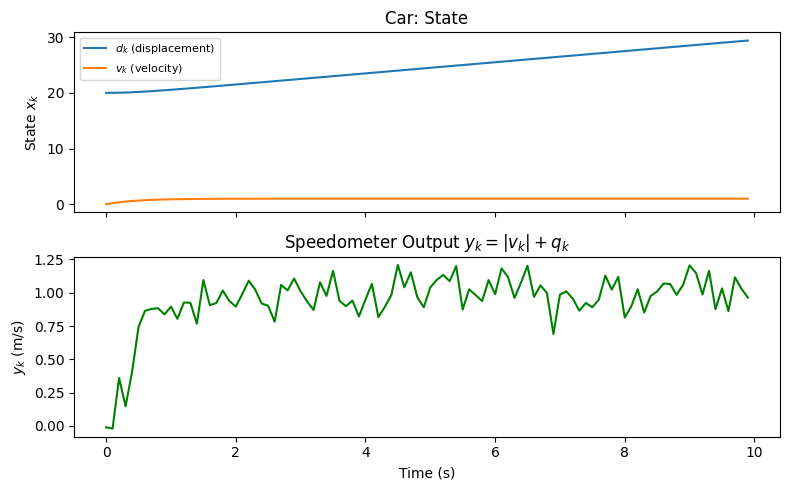

In [15]:
import os

os.makedirs("plots", exist_ok=True)

t_car = np.arange(n_car) * theta_car[2]

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axs[0].plot(t_car, x_car[:, 0], label="$d_k$ (displacement)")
axs[0].plot(t_car, x_car[:, 1], label="$v_k$ (velocity)")
axs[0].set_ylabel("State $x_k$")
axs[0].set_title("Car: State")
axs[0].legend(fontsize=8)
axs[1].plot(t_car, y_car, color="green")
axs[1].set_ylabel("$y_k$ (m/s)")
axs[1].set_xlabel("Time (s)")
axs[1].set_title("Speedometer Output $y_k = |v_k| + q_k$")
plt.tight_layout()
plt.savefig("plots/car_with_speedometer.png", dpi=200, bbox_inches="tight")
plt.show()

![State and speedometer output of the car under a constant force.](plots/car_with_speedometer.png)


### Example: Signal Generators (II-A2)

A sine wave generator can be cast as either a stateless or a stateful system.

**Stateless** $(*, h_{\sin})$. Let $t_k$ be time and $\theta_{\sin} = (A, \omega, t_k)$, where $A$ is the amplitude and $\omega$ the frequency:

$$(*, h_{\sin})(*, *, \theta_{\sin}) = (*,\, A\sin(\omega t_k))$$


In [16]:
def hsin(tk: float, A: float = 1.0, omega: float = 1.0) -> float:
    return A * np.sin(omega * tk)

```{admonition} Passing parameters
:class: tip
Throughout this notebook we will implement the parameters $\theta$ as either a tuple/dictionary of values, or as a sequence of args/kwargs like above. The latter can be particularly useful for playing with values, and we will use it often. The order of the parameters, of course, does not matter.
```

In [17]:
sin = dn.DynamicalSystem(h=hsin)  # (*, hsin)
print(sin)

tk_values = np.arange(0.0, 20.0, 0.05)
u_hist = []
for tk in tk_values:
    _, uk = sin.step(tk=tk, A=1.0, omega=1.0)
    u_hist.append(uk)

(*, hsin)


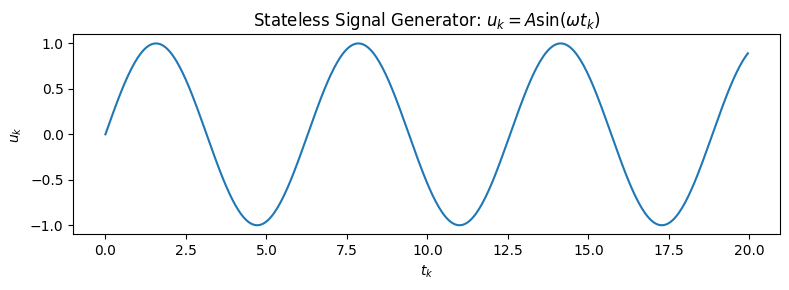

In [18]:
import os

os.makedirs("plots", exist_ok=True)

plt.figure(figsize=(8, 3))
plt.plot(tk_values, u_hist)
plt.xlabel("$t_k$")
plt.ylabel("$u_k$")
plt.title("Stateless Signal Generator: $u_k = A\\sin(\\omega t_k)$")
plt.tight_layout()
plt.savefig("plots/sin_stateless.png", dpi=200, bbox_inches="tight")
plt.show()

![Output of the stateless sine generator.](plots/sin_stateless.png)


**Stateful** $(f_{\sin}, h_{\sin})$. Let $t_k$ be the sole state variable and $\theta_{\sin} = (A, \omega, \Delta t)$:

$$(f_{\sin}, h_{\sin})(t_k, *, \theta_{\sin}) = (t_{k+1}, u_k) = (t_k + \Delta t,\; A\sin(\omega t_k))$$

The output function is the same `hsin`; only the evolution function `fsin` is new.


In [19]:
def fsin(tk: float, dt: float = 0.1) -> float:
    return tk + dt

Now the generator tracks time itself. The loop only feeds back the state returned by the previous step.

In [20]:
sin_stateful = dn.DynamicalSystem(f=fsin, h=hsin)  # (fsin, hsin)
print(sin_stateful)

tk, dt_sin = 0.0, 0.1
t_sin, u_sin = [], []
for _ in range(200):
    tk_next, uk = sin_stateful.step(tk=tk, A=1.0, omega=1.0, dt=dt_sin)
    t_sin.append(tk)
    u_sin.append(uk)
    tk = tk_next

(fsin, hsin)


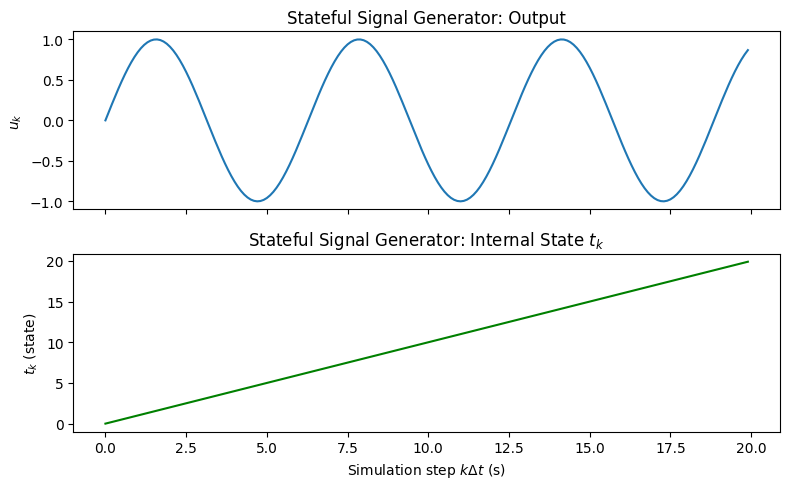

In [21]:
import os

os.makedirs("plots", exist_ok=True)

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axs[0].plot(t_sin, u_sin)
axs[0].set_ylabel("$u_k$")
axs[0].set_title("Stateful Signal Generator: Output")
axs[1].plot(np.arange(len(t_sin)) * dt_sin, t_sin, color="green")
axs[1].set_ylabel("$t_k$ (state)")
axs[1].set_xlabel("Simulation step $k \\Delta t$ (s)")
axs[1].set_title("Stateful Signal Generator: Internal State $t_k$")
plt.tight_layout()
plt.savefig("plots/sin_stateful.png", dpi=200, bbox_inches="tight")
plt.show()

![Output and internal state of the stateful sine generator.](plots/sin_stateful.png)

### Example: Composing Dynamical Systems (II-A3)

Suppose we wish to model the car of II-A1 under an open-loop control input $u_k$ generated by the stateless sine generator of II-A2. We compose systems by plugging the output $u_k$ of $(*, h_{\sin})$ into the argument $u_k$ of $(f_{car}, h_{sp})$. Compactly:

$$(*, h_{\sin}) \xrightarrow{u_k} (f_{car}, h_{sp}).$$

More formally, as a system of equations:

$$\begin{aligned}(*, u_k) &= (*, h_{\sin})(*, *, \theta_{\sin}) \\ (x_{k+1}, y_k) &= (f_{car}, h_{sp})(x_k, u_k, [\theta_{car}, \theta_{sp}])\end{aligned}$$


In [22]:
dt_c = 0.1
t_sim = np.arange(0.0, 20.0, dt_c)
theta_car = (20.0, 39.0, dt_c)
xk = (20.0, 0.0)  # initial [displacement, velocity]
u_comp, v_comp, y_comp = [], [], []

for tk in t_sim:
    _, uk = sin.step(tk=tk, A=39.0, omega=1.0)  # (*, hsin) -> u_k
    xk_next, yk = car_with_spd.step(xk=xk, uk=uk, theta_car=theta_car, sigma=0.1)
    u_comp.append(uk)
    v_comp.append(xk[1])
    y_comp.append(yk)
    xk = xk_next

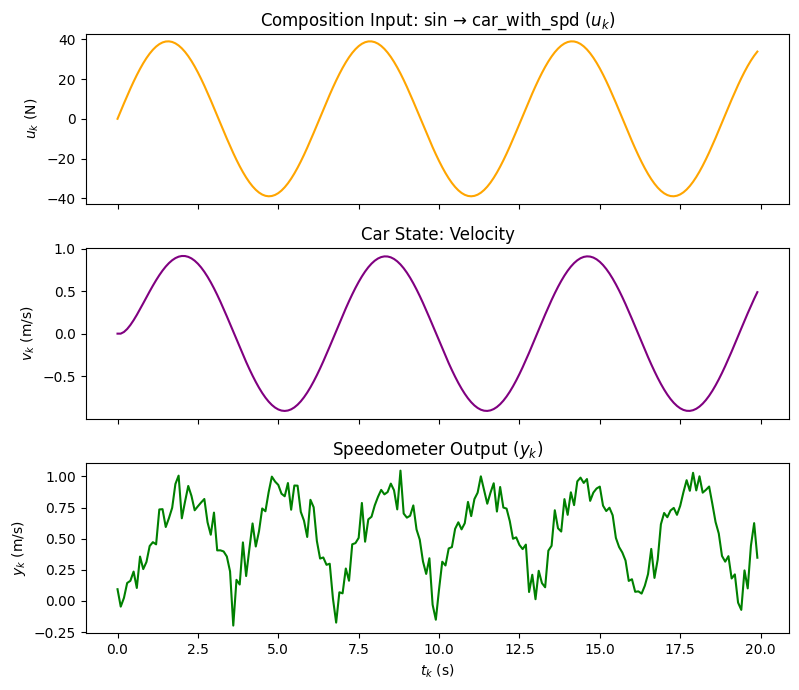

In [23]:
import os

os.makedirs("plots", exist_ok=True)

fig, axs = plt.subplots(3, 1, sharex=True, figsize=(8, 7))
axs[0].plot(t_sim, u_comp, color="orange")
axs[0].set_ylabel("$u_k$ (N)")
axs[0].set_title("Composition Input: sin → car_with_spd ($u_k$)")
axs[1].plot(t_sim, v_comp, color="purple")
axs[1].set_ylabel("$v_k$ (m/s)")
axs[1].set_title("Car State: Velocity")
axs[2].plot(t_sim, y_comp, color="green")
axs[2].set_ylabel("$y_k$ (m/s)")
axs[2].set_xlabel("$t_k$ (s)")
axs[2].set_title("Speedometer Output ($y_k$)")
plt.tight_layout()
plt.savefig("plots/sin_to_car_composition.png", dpi=200, bbox_inches="tight")
plt.show()

![Sine generator input, car velocity and speedometer output for the composed system.](plots/sin_to_car_composition.png)

### Discrete-time Diagrams (II-B)

We will defer the basics of discrete-time diagrams to the paper. This will be important to know for the Overview of Workflow (III-A) section.

## Installation (ROS)

<details>
<summary><b>Click to show the installation instructions for the <code>ROSNode</code> half</b></summary>

The [`ROSNode`](https://nehalsinghmangat.github.io/dynamicalnodes/api/rosnode.html#dynamicalnodes.rosnode.ROSNode) half of the notebook additionally needs

- **ROS2 Jazzy** (primary platform: Ubuntu 24.04). Follow the [official ROS2 Jazzy installation instructions](https://docs.ros.org/en/jazzy/Installation.html) for your platform.
- A virtual environment that can see ROS2's Python packages.

**Letting your venv see ROS2**

ROS2's Python packages (`rclpy`, `std_msgs`, etc...) are not installed by `pip`, so a plain venv cannot see them. If you created your venv as in [Installation (base)](#installation-base), enable system packages for it (no need to delete anything):

```bash
python3 -m venv --system-site-packages .venv
source .venv/bin/activate
```

For a brand-new venv, simply create it with `--system-site-packages` from the start.

**Sourcing ROS2**

Installing ROS2 does not activate it: you must **source** its setup file in every new terminal, which makes `ros2`, `rclpy`, and the message packages available in that shell:

```bash
source /opt/ros/jazzy/setup.bash
```

Verify that the right version is active:

```bash
printenv ROS_DISTRO   # should print: jazzy
ros2 --version
```

If `ROS_DISTRO` is empty, ROS2 is not sourced in this shell. If it prints a different distribution (for example `humble`), another version is sourced instead. Only one distribution can be active per shell, so source the one you want explicitly.

To make Jazzy the default in every new terminal, add the line to `~/.bashrc` (replacing any existing `source /opt/ros/.../setup.bash` line):

```bash
echo "source /opt/ros/jazzy/setup.bash" >> ~/.bashrc
```

````{note}
**The order matters for Jupyter.** Start it from a terminal where ROS2 is sourced *and* your venv is active, so the notebook's Python can see both:

```bash
source /opt/ros/jazzy/setup.bash
source .venv/bin/activate
jupyter lab
```
````

**Optional: PlotJuggler**

[PlotJuggler](https://plotjuggler.io/) is used near the end of the notebook to watch live ROS signals. You can install it now or when you get there:

```bash
sudo apt-get install -y ros-jazzy-plotjuggler-ros
```

Launch it (with ROS2 sourced) with `ros2 run plotjuggler plotjuggler`.

</details>

Check that the notebook can see ROS2:

In [24]:
# Necessary for ROSNode section
try:
    import rclpy
    from std_msgs.msg import Float64

    print("ROS2 Python packages found.")
except ImportError as e:
    print("ROS2 is not visible from this notebook:", e)
    print("Source ROS2 and activate your venv in the terminal, then restart Jupyter.")

ROS2 Python packages found.


## The Robot Operating System (II-C)

We will defer the basics of ROS 2 to the [official documentation](https://docs.ros.org). This will be important to know for the Overview of Workflow (III-A) section.

## Overview of Workflow (III-A)

Both discrete-time diagrams and ROS graphs are *homogeneous directed graphs*: there is one type of node and one type of directed arrow in each. The blocks and composition arrows of a discrete-time diagram correspond to the ROS nodes and topic arrows of a ROS graph.  `dynamicalnodes` exploits this correspondence to cast the former into the latter. This is the workflow:

1. **Theory.** Cast the control system into a discrete-time diagram. If you have a continuous-time model, integration (Euler, RK4, ...) is always an option for discretization, and for linear systems the matrix exponential gives an exact translation. Then derive the $(f, *)$, $(*, h)$, or $(f, h)$ pair for every block.

![The discrete-time diagram of an abstract feedback system.](../../_static/figures/feedback_diagram_discrete_time.svg)

2. **Python.** Implement every $f$ and $h$ in Python and encapsulate each block in a [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) object. The wires become ordinary variable assignments: the output of one object is passed as an input to another. The whole system can then be simulated with a standard for-loop, as we've already seen.

![The feedback system implemented with DynamicalSystem objects.](../../_static/figures/feedback_diagram_dynamicalsystem_objects.svg)

3. **ROS.** Pass every `DynamicalSystem` into a [`ROSNode`](https://nehalsinghmangat.github.io/dynamicalnodes/api/rosnode.html#dynamicalnodes.rosnode.ROSNode) constructor along with ROS metadata. `ROSNode` objects get two kinds of testing. First they are simulated in a for-loop to check that the ROS ↔ Python data-type translation is correct. Then each is written to an `rclpy` file from which live ROS nodes are spun, and the graph as a whole is tested. The wires become subscriptions and publications to topics.

![The feedback system implemented as ROS nodes.](../../_static/figures/feedback_diagram_rosnode.svg)

This section will cover the last step in this workflow. Conceptually, the `ROSNode` is nothing but a wrapper that wraps a `DynamicalSystem` with ROS-specific metadata and generates rclpy files.

## The `ROSNode` Class (III-C)

[`ROSNode`](https://nehalsinghmangat.github.io/dynamicalnodes/api/rosnode.html#dynamicalnodes.rosnode.ROSNode) wraps a [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) with ROS-specific metadata. The whole idea is to use the `DynamicalSystem` graph already validated in the previous step to create a corresponding live graph of ROS nodes.

Obviously, there are two obstacles when using `DynamicalSystem` objects as the computational core of our ROS nodes:

1. type translation from ROS to Python to ROS again needs to occur
2. we need some form of data handling (e.g. data queues) to deal with the asynchronous data streams typical of ROS.

The figure below gives a good idea of what this looks like

![The modularity of the dynamicalnodes pipeline: (a) a DynamicalSystem "plant" block; (b) a ROSNode wrapping the same block behind an incoming queue, a ros2py converter, an internal state loop, a py2ros converter, and an outgoing queue; (c) the final spun ROS node exposing only its topics.](../../_static/figures/modularity.svg)

- **(a)** the raw `DynamicalSystem`.
- **(b)** `ROSNode`'s encapsulation of it: an incoming message is queued, converted by `ros2py`, fed to the same block from (a) with its state looping back internally, converted back by `py2ros`, and queued again before publishing.
- **(c)** the final spun ROS node, exposing only its topics. Each step builds on a validated component of the previous one.

### Testing Data Translation
Consider the car under a control input [II-A3](#example-composing-dynamical-systems-ii-a3). We have two [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) objects: the sin wave generator, and the car with speedometer object. We wrap both of them into [`ROSNode`](https://nehalsinghmangat.github.io/dynamicalnodes/api/rosnode.html#dynamicalnodes.rosnode.ROSNode) objects with data pipeline metadata and test, with the same for loop as before, that the data translation from ROS to Python to ROS works and that we have the expected behaviour. See the API for constructor details.

```{admonition} Skill: wrap-in-rosnode and write-ros-converters
:class: tip
The [`wrap-in-rosnode`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/wrap-in-rosnode) skill covers choosing topics and message types, filling in `subs`/`pubs`/`state_name`, and verifying the ROSNode loop against the Python loop. If your message type has no converter in [`ros2py_py2ros`](https://nehalsinghmangat.github.io/dynamicalnodes/api/ros2py_py2ros.html), use [`write-ros-converters`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/write-ros-converters) to write and test a `ros2py_*`/`py2ros_*` pair.
```

In [25]:
from std_msgs.msg import Float64

from dynamicalnodes import ROSNode
from dynamicalnodes.ros2py_py2ros import ros2py_float64, py2ros_float64

# sin generator node
sin_node = ROSNode(
    dynamical_system=sin,
    pubs=[{"topic": "/uk", "msg_type": Float64, "py2ros": py2ros_float64}],
)

# car with speedometer node
car_with_spd_node = ROSNode(
    dynamical_system=car_with_spd,
    state_name="xk",
    subs=[{"topic": "/uk", "msg_type": Float64, "arg": "uk", "ros2py": ros2py_float64}],
    pubs=[{"topic": "/yk", "msg_type": Float64, "py2ros": py2ros_float64}],
)

# test composition: sin_node -> car_with_spd_node
# xk is passed on the first call; afterwards the node tracks it internally.
uk_msg = sin_node.step(tk=2.1, A=1.0, omega=1.0)
yk_msg = car_with_spd_node.step(xk=(20.0, 0.0), uk=uk_msg, theta_car=(20.0, 39.0, 0.1))
print(uk_msg.data, yk_msg.data, car_with_spd_node.state)

0.8632093666488737 -0.2815873101725092 (20.0, np.float64(0.004316046833244369))


**Simulating the nodes.** This loop mirrors the one in [II-A3](#example-composing-dynamical-systems-ii-a3), with `sin_node` and `car_with_spd_node` in place of `sin` and `car_with_spd`. `car_with_spd_node` is stateful (`state_name="xk"`), so unlike in the [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) loop the state is "hidden"; we can only read/write to it through `.state`. The inputs and outputs of `.step()` are now ROS messages. The dashed curves in the plot below are the `DynamicalSystem` results from II-A3, and the two should overlay up to speedometer noise.

In [26]:
car_with_spd_node._state = (20.0, 0.0)  # reset the node to the initial state
theta_car = (20.0, 39.0, dt_c)
u_ros, v_ros, y_ros = [], [], []

for tk in t_sim:
    uk_msg = sin_node.step(tk=tk, A=39.0, omega=1.0)  # (*, hsin) -> u_k
    v_ros.append(car_with_spd_node.state[1])  # velocity before this step
    yk_msg = car_with_spd_node.step(uk=uk_msg, theta_car=theta_car, sigma=0.1)
    # NOTE: u_ros and y_ros now hold ROS types (std_msgs/Float64), not floats,
    # so we must translate them back to Python in order to plot them.
    u_ros.append(uk_msg)
    y_ros.append(yk_msg)

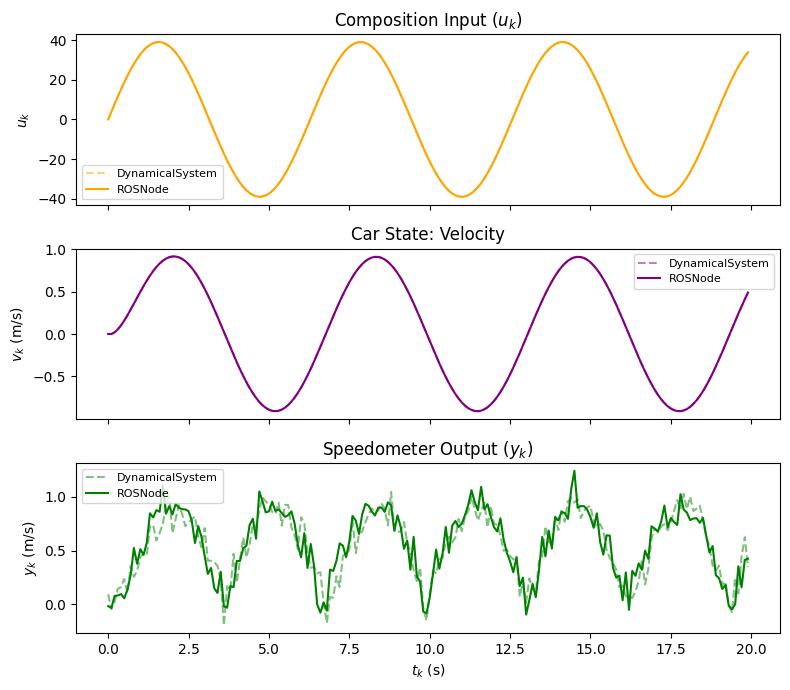

In [27]:
import os

os.makedirs("plots", exist_ok=True)

# translate ROS -> Python for plotting
u_ros_py = [msg.data for msg in u_ros]
y_ros_py = [msg.data for msg in y_ros]

fig, axs = plt.subplots(3, 1, sharex=True, figsize=(8, 7))
for ax, ds, ros, color, ylabel, title in [
    (axs[0], u_comp, u_ros_py, "orange", "$u_k$", "Composition Input ($u_k$)"),
    (axs[1], v_comp, v_ros, "purple", "$v_k$ (m/s)", "Car State: Velocity"),
    (axs[2], y_comp, y_ros_py, "green", "$y_k$ (m/s)", "Speedometer Output ($y_k$)"),
]:
    ax.plot(t_sim, ds, color=color, linestyle="--", alpha=0.5, label="DynamicalSystem")
    ax.plot(t_sim, ros, color=color, label="ROSNode")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
axs[2].set_xlabel("$t_k$ (s)")
plt.tight_layout()
plt.savefig("plots/toy_node_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

![DynamicalSystem versus ROSNode results for the composed toy system.](plots/toy_node_comparison.png)

We have confirmed that the translation from ROS to Python to ROS again doesn't break anything! The [`ros2py_py2ros`](https://nehalsinghmangat.github.io/dynamicalnodes/api/ros2py_py2ros.html#module-dynamicalnodes.ros2py_py2ros) module ships `ros2py_<type>`/`py2ros_<type>` pairs for common `geometry_msgs`, `nav_msgs`, `sensor_msgs`, and `std_msgs` types. To support a new message type, write a pair of your own and pass them in the `ros2py`/`py2ros` keys. Incidentally, this is what the functions we used above look like.

In [28]:
import inspect

print(inspect.getsource(ros2py_float64))
print(inspect.getsource(py2ros_float64))

def ros2py_float64(msg: Float64) -> float:
    """Convert Float64 message to Python float."""
    return float(msg.data)

def py2ros_float64(arr: NDArray) -> Float64:
    """Convert scalar or 1D array to Float64 message."""
    msg = Float64()
    arr = np.asarray(arr, dtype=float).ravel()
    msg.data = float(arr[0]) if arr.size > 0 else 0.0
    return msg



### Generating `rclpy` files


After confirming the type translation works well, we write each node to a standalone `rclpy` file. [`write_ROSNode_to_rclpy()`](https://nehalsinghmangat.github.io/dynamicalnodes/api/rosnode.html#dynamicalnodes.rosnode.ROSNode.write_ROSNode_to_rclpy) inlines the source of `f`, `h`, and the translation functions into a file that spins a real ROS node. The arguments that the for loop supplied by hand now go into the file instead: `initial_state` replaces the `xk` we initialized, and `static_params` holds the fixed keyword arguments we passed to every `.step()` call (`A`, `omega`, `theta_car`, `sigma`). For more options/details, see the API.

```{admonition} Skill: deploy-rosnodes-to-rclpy
:class: tip
For choosing `sync_mode`, `timer_hz`, `stale_after`, `initial_inputs` and the parameter types, converting simulation `dt` to node rates, running the nodes, and debugging a node that does nothing, use the [`deploy-rosnodes-to-rclpy`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/deploy-rosnodes-to-rclpy) skill.
```

In [29]:
import os

os.makedirs("./toy_ros_nodes", exist_ok=True)

sin_node.write_ROSNode_to_rclpy(
    "./toy_ros_nodes/sin_node.py",
    node_name="sin_generator",
    timer_hz=1 / dt_c,  # 10 Hz; see "Sim Time to Node Time" below
    static_params={"A": 39.0, "omega": 1.0},
)
car_with_spd_node.write_ROSNode_to_rclpy(
    "./toy_ros_nodes/car_with_spd_node.py",
    node_name="car_with_speedometer",
    initial_state=(20.0, 0.0),
    static_params={"theta_car": (20.0, 39.0, dt_c), "sigma": 0.1},
)
print("Written: sin_node.py  car_with_spd_node.py")

Written: sin_node.py  car_with_spd_node.py


### Sim Time to Node Time

In the for loop, time is just an index: step $k$ happens at $t_k = k\,\Delta t$ and the loop runs as fast as the computer allows. A live ROS graph has no loop, so something else must decide *when* each step happens. The conversion is

$$\text{timer\_hz} = \frac{1}{\Delta t}, \qquad \Delta t = 0.1\ \text{s} \;\Rightarrow\; 10\ \text{Hz}.$$

Because everything downstream is callback based, **only the reference node needs a rate**. `sin_node` has no subscriptions, so nothing would ever trigger it; it needs `timer_hz`. `car_with_spd_node` is triggered by its subscription: each message on `/uk` fires one step, which publishes `/yk`. The car therefore inherits the 10 Hz of the sine generator without being told, and any further nodes downstream (a controller, a filter) would do the same.

Two things carry the rest of the sim-time bookkeeping:

- **The model's $\Delta t$ stays a parameter.** `fcar` still integrates over `dt_c = 0.1`, which is baked in through `static_params`. The node only has the right physics if messages really arrive every $\Delta t$, so `timer_hz` and the model's $\Delta t$ must agree.
- **$t_k$ becomes wall-clock time.** The generated sine node computes `tk` as the seconds elapsed since the node started, so $t_k$ is no longer a loop variable we choose but the node's own clock.

```{admonition} What write_ROSNode_to_rclpy() requires of f and h
:class: warning
The generator copies the *source text* of your functions into the node file, so:

- They must be **named functions**; a `lambda` raises a `ValueError`.
- Their source must be **retrievable** (defined in a notebook or `.py` file). Anything `inspect.getsource` cannot read, such as C extensions, raises an `OSError`; wrap it with `deps=`.
- They must be **self-contained**: helper functions they call go in `deps=`.
- Every parameter must be **supplied at runtime** by a subscription `arg`, the `state_name`, `static_params`, `dynamic_params`, `tk`, or a default value. Otherwise it is `None`.
```

### Running the Nodes
Unlike the cruise-control system we'll see later in Section IV, we don't bother writing a launch file here. Instead, we start the ROS nodes directly and open `rqt_graph` to confirm everything is wired up correctly.

```bash
python3 toy_ros_nodes/sin_node.py &
python3 toy_ros_nodes/car_with_spd_node.py &
rqt_graph
```

Here is `rqt_graph`, captured from an actual run of these two files:

![Live rqt_graph of the toy example: sin_generator publishes /uk into car_with_speedometer.](toy_rqt_graph_live.png)

Hooray! Everything looks good. Two nodes, one topic. (the `/yk` output does not appear because nothing subscribes to it and `rqt_graph` hides leaf topics by default.)

We can see the values of the topics live using ros2 topic, but [PlotJuggler](https://plotjuggler.io/) shows the signal values live in a GUI. Rather than wiring it up by hand in the GUI, we can save a layout file describing the plots you want as XML and pass it on the command line:

```bash
source /opt/ros/jazzy/setup.bash
ros2 run plotjuggler plotjuggler --layout toy_layout.xml -p
```

`-p`/`--publish` auto-starts the streaming subscriber the layout specifies, so the only manual step is a one-time "Start Streaming?" confirmation. `toy_layout.xml` declares two curves, `/uk/data` and `/yk/data`, in a two-panel grid.

![PlotJuggler streaming live /uk and /yk data from the toy example.](toy_plotjuggler_live.gif)

## Example: Car Cruise Control (IV)

We take a car with cruise control, a standard closed-loop feedback system, through the full `dynamicalnodes` pipeline. Each block of the general feedback system is implemented as follows:

- reference generator = cruise control button (sinusoidal setpoint)
- controller = PID control
- plant = car + speedometer
- observer = Kalman filter

The car velocity tracks a sinusoidal reference. A Kalman filter estimates the car's velocity from noisy speedometer measurements and feeds the estimate back to the PID controller. For each block we derive the $(f, h)$ pair and show its Python implementation.

![The cruise control block diagram.](../../_static/figures/feedback_diagram_discrete_time.svg)

Where a parameter is normally fixed for a given deployment (`A`, `omega`, `m`, `b`, `dt`), the functions below give it a default matching the tuning used in the simulation, so each block also works standalone.

### Linear Longitudinal Vehicle with Measurements (IV-A)

The plant is the car with speedometer of II-A1, but the only state of interest is velocity. We rederive $f_{car}$, $h_{sp}$, and the combined system.

**Car dynamics** $(f_{car}, *)$. The state is the scalar $x_k = v_k$, the control input is $u_k$, and $\theta_{car} = (m, b, \Delta t)$:

$$(f_{car}, *)(x_k, u_k, \theta_{car}) = \left(v_k + \Delta t\left(\dfrac{u_k - b v_k}{m}\right),\, *\right)$$

**Speedometer** $(*, h_{sp})$, with $\theta_{sp} = (\sigma)$ and $q_k \sim \mathcal{N}(0, \sigma^2)$:

$$(*, h_{sp})(x_k, u_k, \theta_{sp}) = (*,\, |v_k| + q_k)$$

The noise is generated *inside* `hcar` rather than added in the simulation loop. The combined plant is $(f_{car}, h_{sp})(x_k, u_k, [\theta_{car}, \theta_{sp}]) = (x_{k+1}, y_k)$.

**Paper listing: plant.**

In [30]:
import numpy as np
from dynamicalnodes import DynamicalSystem


# car dynamics
def fcar(
    xk: float, uk: float, m: float = 1500.0, b: float = 50.0, dt: float = 1.0
) -> float:
    vk = xk
    return vk + dt * (uk - b * vk) / m


# speedometer
def hcar(xk: float, sigma: float = 0.0) -> float:
    vk = xk
    return np.abs(vk) + np.random.normal(0.0, sigma)


# encapsulate as a single DynamicalSystem object
plant = DynamicalSystem(f=fcar, h=hcar)
print(plant)  # (fcar, hcar)

(fcar, hcar)


### Sinusoidal Reference Generator (IV-B)

We use a stateless sinusoidal generator, $(*, h_r)$ with $r_k = A \sin(\omega t_k)$ (see II-A2 for the derivation and III-B for the same code). It is computed directly from $t_k$, so no dynamics function is needed.

**Paper listing: reference generator.**

In [31]:
def href(tk: float, A: float = 30.0, omega: float = np.pi / 60) -> float:
    return A * np.sin(omega * tk)


ref = DynamicalSystem(h=href)
print(ref)  # (*, href)

(*, href)


### PID Controller (IV-C)

Let $r_k$ be the reference and $\hat{x}_k$ the estimated plant state. We assume a 1-D system (floats, no arrays) for simplicity.

**Controller state** $(f_c, *)$. Let $e_k = r_k - \hat{x}_k$ be the current error and $e_{\text{int}_k} = \sum_{j=0}^{k} e_j \Delta t$ the accumulated error. The state is $c_k := (e_{k-1}, e_{\text{int}_k})$ and

$$(f_c, *)(c_k, [r_k, \hat{x}_k], \Delta t) = \big((e_k,\; e_{\text{int}_k} + e_k \Delta t),\, *\big)$$

**PID output** $(*, h_c)$. With gains $K_P$, $K_I$, $K_D$:

$$(*, h_c)(c_k, [r_k, \hat{x}_k], \theta_c) = \Big(*,\; K_P e_k + K_I e_{\text{int}_k} + K_D \tfrac{e_k - e_{k-1}}{\Delta t}\Big)$$

The combined controller is $(f_c, h_c)(c_k, [r_k, \hat{x}_k], \theta_c) = (c_{k+1}, u_k)$.

Two choices in the implementation below are conveniences rather than requirements. `dt` is a separate argument instead of part of $\theta_c$, and `rk` and `xhatk` are two arguments instead of a bundled `[rk, xhatk]`. We also pass `KP`, `KI`, `KD` as separate top-level arguments instead of one $\theta_c = (K_P, K_I, K_D)$. That is what lets IV-E register them individually as `dynamic_params`, tunable live with `ros2 param set` while the node runs.

**Paper listing: PID controller.**

In [32]:
# controller state update
def fpid(
    ck: tuple[float, float],
    rk: float,
    xhatk: float,
    KP: float = 500.0,
    KI: float = 30.0,
    KD: float = 10.0,
    dt: float = 1.0,
) -> tuple[float, float]:
    """Update PID state: returns (prev_error, integral)."""
    e_prev, e_int = ck
    ek = rk - xhatk
    return (ek, e_int + ek * dt)


# PID output
def hpid(
    ck: tuple[float, float],
    rk: float,
    xhatk: float,
    KP: float = 500.0,
    KI: float = 30.0,
    KD: float = 10.0,
    dt: float = 1.0,
) -> float:
    """Compute control output from current PID state."""
    e_prev, e_int = ck
    ek = rk - xhatk
    e_der = (ek - e_prev) / dt
    return KP * ek + KI * e_int + KD * e_der


# encapsulate as a single DynamicalSystem object
pid = DynamicalSystem(f=fpid, h=hpid)
print(pid)  # (fpid, hpid)

(fpid, hpid)


### Linear Kalman Filter (IV-D)

We write the filter in its recursive *prior* form: the state is the estimate of $x_k$ given data up to $k-1$. Let $\hat{x}_k := \hat{x}_{k|k-1}$ and $P_k := P_{k|k-1}$ be the estimate and its covariance, so the filter state is $o_k := (\hat{x}_k, P_k)$. The inputs are the control $u_k$ and the plant measurement $y_k$, and the parameters are $\theta_o = \{F_k, H_k, B_k, Q_k, R_k\}$: the linearized plant dynamics, measurement, and control matrices, and the process and measurement noise covariances. The code below is written in matrix form, so it applies to a state of any dimension. In this example the plant state is the scalar $v_k$, so every matrix is $1 \times 1$.

**Update and predict** $(f_o, *)$. Because $y_k$ measures $x_k$, it corrects the estimate of $x_k$ first. The *update* step is

$$S = H_k P_k H_k^\top + R_k, \quad K = P_k H_k^\top S^{-1}, \quad \hat{x}_{k|k} = \hat{x}_k + K(y_k - H_k \hat{x}_k), \quad P_{k|k} = (I - K H_k)P_k,$$

and the *predict* step with the control $u_k$ then advances the estimate to $k+1$:

$$\hat{x}_{k+1} = F_k \hat{x}_{k|k} + B_k u_k, \qquad P_{k+1} = F_k P_{k|k} F_k^\top + Q_k.$$

**State estimate** $(*, h_o)$ returns the prior estimate directly: $(*, h_o)(o_k, \dots) = (*, \hat{x}_k)$. This is available at the start of step $k$, before $y_k$ exists, which matches the convention that $h$ sees the pre-update state. The combined Kalman filter is $(f_o, h_o)(o_k, [u_k, y_k], \theta_o) = (o_{k+1}, \hat{x}_k)$.

**One feedback cycle at step $k$.** Every block reads its step-$k$ values and every state moves to $k+1$ together:

1. Controller: $u_k = h_c(c_k, [r_k, \hat{x}_k])$.
2. Plant: $(x_{k+1}, y_k) = (f_p, h_p)(x_k, u_k)$.
3. Kalman filter: $(o_{k+1}, \hat{x}_k) = (f_o, h_o)(o_k, [u_k, y_k])$.

In the simulation loop and the ROS graph the estimate $\hat{x}_k$ that the filter returns at step $k$ reaches the controller at step $k+1$, a one-sample feedback delay.

To support the asynchronous operation described in III-E, `uk` and `yk` are both optional in the implementation: update runs only when `yk` is present and predict only when `uk` is present. With `sync_mode="any"` each subscription triggers the node independently, so a step may see just one of them. Variations such as the Square-Root, Consider, and Augmented Information Kalman filters only require changing `fkf`; the rest of the pipeline is unchanged.

**Paper listing: Kalman filter.**


In [33]:
# update and predict
def fkf(
    ok: tuple[np.ndarray, np.ndarray],
    Fk: np.ndarray,
    Bk: np.ndarray,
    Hk: np.ndarray,
    Qk: np.ndarray,
    Rk: np.ndarray,
    uk: np.ndarray | None = None,
    yk: np.ndarray | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Discrete Kalman filter in prior form: ok = (xhat_{k|k-1}, P_{k|k-1}).

    Update with yk (the measurement of x_k), then predict with uk to give
    ok_next = (xhat_{k+1|k}, P_{k+1|k}). Both uk and yk are optional: update
    runs only when yk is fresh, predict only when uk is fresh. With
    sync_mode="any" each subscription triggers the node independently, so a
    step may see just one of them.
    """
    xhat, P = ok
    # Update
    if yk is not None:
        S = Hk @ P @ Hk.T + Rk
        K = P @ Hk.T @ np.linalg.inv(S)
        xhat = xhat + K @ (np.atleast_1d(yk) - Hk @ xhat)
        P = (np.eye(len(xhat)) - K @ Hk) @ P
    # Predict
    if uk is not None:
        xhat = Fk @ xhat + Bk @ np.atleast_1d(uk)
        P = Fk @ P @ Fk.T + Qk
    return (xhat, P)


# state estimate output
def hkf(ok: tuple[np.ndarray, np.ndarray]) -> np.ndarray:
    xhat, P = ok
    return xhat


kf = DynamicalSystem(f=fkf, h=hkf)
print(kf)  # (fkf, hkf)


(fkf, hkf)


### Simulating the Discrete-Time Diagram

With every block defined, the whole feedback system is simulated with a for-loop. Each block's `.step(**kwargs)` returns `(x_{k+1}, y_k)`, and `y_k` is computed from the *pre-update* state: `xk_next, yk = plant.step(xk=xk, ...)` returns the plant's next state together with the measurement of its *current* (not yet advanced) state. The loop advances every block's state only after collecting that step's outputs.

```{admonition} Skill: simulate-with-dynamicalsystem
:class: tip
The ordering rules used in this loop (signal-flow order, initial feedback value, advancing all states together, the prior-form Kalman filter) are spelled out in the [`simulate-with-dynamicalsystem`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/simulate-with-dynamicalsystem) skill.
```

In [34]:
# Simulation Time
dt = 1.0
t_sim = np.arange(0, 60, dt)

# ── Parameters ──────────────────────────────────────────────
# Reference
A_ref = 30.0
omega_ref = np.pi / 60.0  # rad/s, full period 120 s

# PID
KP, KI, KD = 500.0, 30.0, 10.0

# Car
m, b = 1500.0, 50.0

# Kalman filter (1x1 matrices: velocity-only state)
Fk = np.array([[1.0 - (b / m) * dt]])
Bk = np.array([[dt / m]])
Hk = np.array([[1.0]])  # observe velocity directly
Qk = np.array([[0.1]])
Rk = np.array([[2.0]])

# Measurement noise std for the speedometer, generated inside hcar
v_noise_std = np.sqrt(Rk[0, 0])

# ── Initial States ──────────────────────────────────────────
ck = (0.0, 0.0)  # PID: (e_prev, e_int)
xk = 0.0  # plant: velocity
ok = (np.zeros(1), np.eye(1))  # KF: (xhat, P)

# ── Initial Inputs ──────────────────────────────────────────
xhatk = float(ok[0][0])  # required for first step of the controller

# ── Simulation Memory ───────────────────────────────────────
ref_out, ctrl_out, plant_out, kf_out = [], [], [], []

for tk in t_sim:

    # ── Reference ───────────────────────────────────────────
    _, rk = ref.step(tk=tk, A=A_ref, omega=omega_ref)

    # ── PID (uses the KF's velocity estimate) ───────────────
    ck_next, uk = pid.step(ck=ck, rk=rk, xhatk=xhatk, KP=KP, KI=KI, KD=KD, dt=dt)

    # ── Car (speedometer noise generated inside hcar) ───────
    xk_next, yk = plant.step(xk=xk, uk=uk, m=m, b=b, dt=dt, sigma=v_noise_std)

    # ── Kalman Filter ───────────────────────────────────────
    ok_next, xhat = kf.step(ok=ok, uk=uk, yk=yk, Fk=Fk, Bk=Bk, Hk=Hk, Qk=Qk, Rk=Rk)
    xhatk = float(xhat[0])  # the 1-D controller takes the scalar estimate

    ref_out.append(rk)
    ctrl_out.append(uk)
    plant_out.append(yk)
    kf_out.append(xhatk)

    # ── set k + 1 state ─────────────────────────────────────
    ck, xk, ok = ck_next, xk_next, ok_next

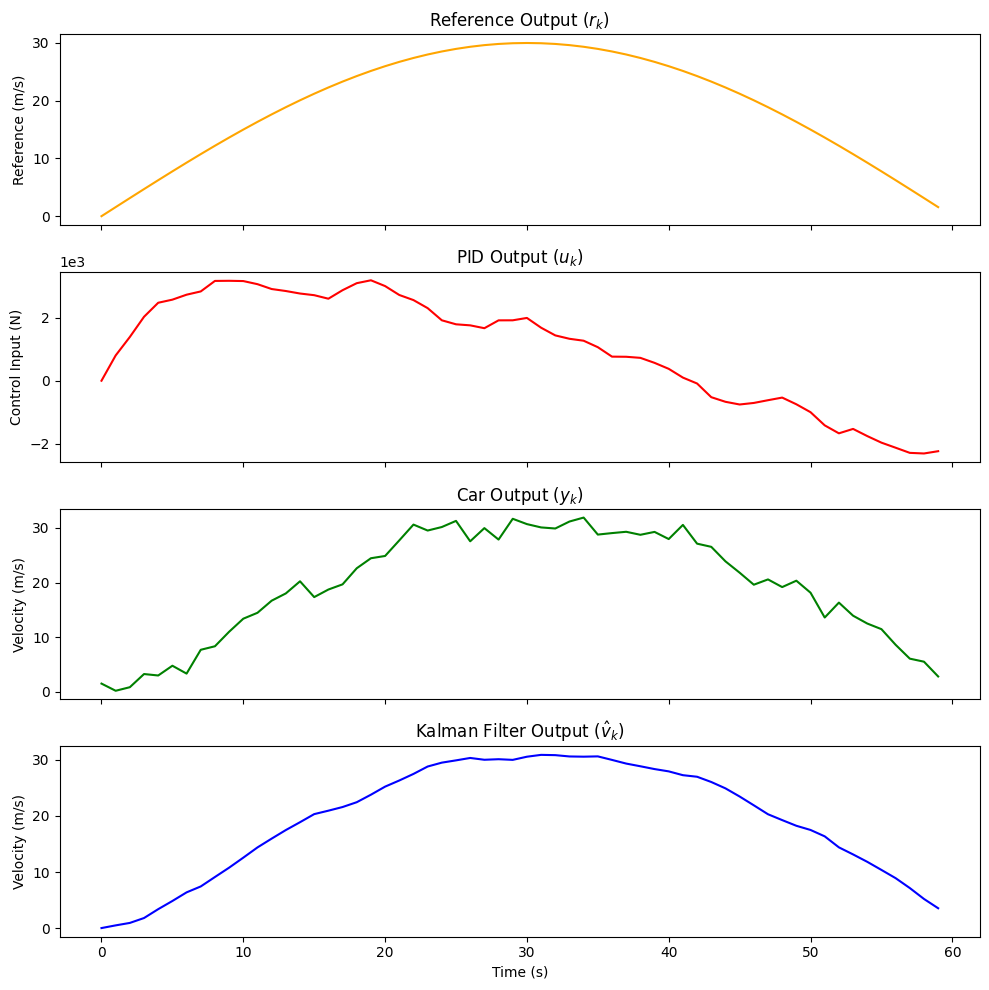

In [35]:
import os

os.makedirs("plots", exist_ok=True)

fig, axs = plt.subplots(4, 1, sharex=True, figsize=(10, 10))

axs[0].plot(t_sim, ref_out, color="orange")
axs[0].set_ylabel("Reference (m/s)")
axs[0].set_title("Reference Output ($r_k$)")

axs[1].plot(t_sim, ctrl_out, color="red")
axs[1].set_ylabel("Control Input (N)")
axs[1].set_title("PID Output ($u_k$)")
axs[1].ticklabel_format(style="sci", axis="y", scilimits=(0, 0))

axs[2].plot(t_sim, plant_out, color="green")
axs[2].set_ylabel("Velocity (m/s)")
axs[2].set_title("Car Output ($y_k$)")

axs[3].plot(t_sim, kf_out, color="blue")
axs[3].set_ylabel("Velocity (m/s)")
axs[3].set_xlabel("Time (s)")
axs[3].set_title("Kalman Filter Output ($\\hat{v}_k$)")

plt.tight_layout()
plt.savefig("plots/car_cruise_control_figure.png", dpi=200, bbox_inches="tight")
plt.show()

![Reference, PID output, car output and Kalman filter output of the cruise-control simulation.](plots/car_cruise_control_figure.png)

### Generating the ROS Graph (IV-E)

After each [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem) block is defined, the [`ROSNode`](https://nehalsinghmangat.github.io/dynamicalnodes/api/rosnode.html#dynamicalnodes.rosnode.ROSNode) class creates an `rclpy` file for each, from which the entire control system can be spun and analyzed with ROS utilities: `ros2 launch` to start the system, `rqt_graph` to visualize the topology, and PlotJuggler to compare the live signals with the Python simulation above.

#### Wrapping the Blocks and Verifying the Converters

First we wrap every block in a `ROSNode` and re-run the same loop through them. The purpose is not to simulate ROS timing behavior but to confirm that the `ros2py`/`py2ros` converters and the `DynamicalSystem` wiring are correct before generating deployment files.

```{admonition} Skill: wrap-in-rosnode and deploy-rosnodes-to-rclpy
:class: tip
To build the same graph for your own system, follow [`wrap-in-rosnode`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/wrap-in-rosnode) to wrap and test each block, then [`deploy-rosnodes-to-rclpy`](https://github.com/nehalsinghmangat/dynamicalnodes/tree/main/.claude/skills/deploy-rosnodes-to-rclpy) to write, run and debug the nodes.
```

In [36]:
ref_node = ROSNode(
    dynamical_system=ref,
    pubs=[{"topic": "/rk", "msg_type": Float64, "py2ros": py2ros_float64}],
)

pid_node = ROSNode(
    dynamical_system=pid,
    subs=[
        {"topic": "/rk", "msg_type": Float64, "arg": "rk", "ros2py": ros2py_float64},
        {
            "topic": "/xhatk",
            "msg_type": Float64,
            "arg": "xhatk",
            "ros2py": ros2py_float64,
        },
    ],
    pubs=[{"topic": "/uk", "msg_type": Float64, "py2ros": py2ros_float64}],
    state_name="ck",
)

plant_node = ROSNode(
    dynamical_system=plant,
    subs=[
        {"topic": "/uk", "msg_type": Float64, "arg": "uk", "ros2py": ros2py_float64},
    ],
    pubs=[{"topic": "/yk", "msg_type": Float64, "py2ros": py2ros_float64}],
    state_name="xk",
)

kf_node = ROSNode(
    dynamical_system=kf,
    subs=[
        {"topic": "/uk", "msg_type": Float64, "arg": "uk", "ros2py": ros2py_float64},
        {"topic": "/yk", "msg_type": Float64, "arg": "yk", "ros2py": ros2py_float64},
    ],
    pubs=[{"topic": "/xhatk", "msg_type": Float64, "py2ros": py2ros_float64}],
    state_name="ok",
)

Same loop as the pure-Python simulation, but every input and output now round-trips through a ROS message type.

In [37]:
# Initial states
pid_node._state = (0.0, 0.0)  # PID: (e_prev, e_int)
plant_node._state = 0.0  # plant: velocity
kf_node._state = (np.zeros(1), np.eye(1))  # KF: (xhat, P)

# Initial inputs
xhatk_ros = Float64(data=0.0)  # bootstrap before the first KF output

ref_node_out, ctrl_node_out, plant_node_out, kf_node_out = [], [], [], []

for tk in t_sim:

    # ── Reference ───────────────────────────────────────────
    rk_ros = ref_node.step(tk=tk, A=A_ref, omega=omega_ref)

    # ── PID ─────────────────────────────────────────────────
    uk_ros = pid_node.step(rk=rk_ros, xhatk=xhatk_ros, KP=KP, KI=KI, KD=KD, dt=dt)

    # ── Plant (speedometer noise generated inside hcar) ─────
    yk_ros = plant_node.step(uk=uk_ros, m=m, b=b, dt=dt, sigma=v_noise_std)

    # ── Kalman Filter ───────────────────────────────────────
    xhatk_ros = kf_node.step(uk=uk_ros, yk=yk_ros, Fk=Fk, Bk=Bk, Hk=Hk, Qk=Qk, Rk=Rk)

    ref_node_out.append(rk_ros.data)
    ctrl_node_out.append(uk_ros.data)
    plant_node_out.append(yk_ros.data)
    kf_node_out.append(xhatk_ros.data)

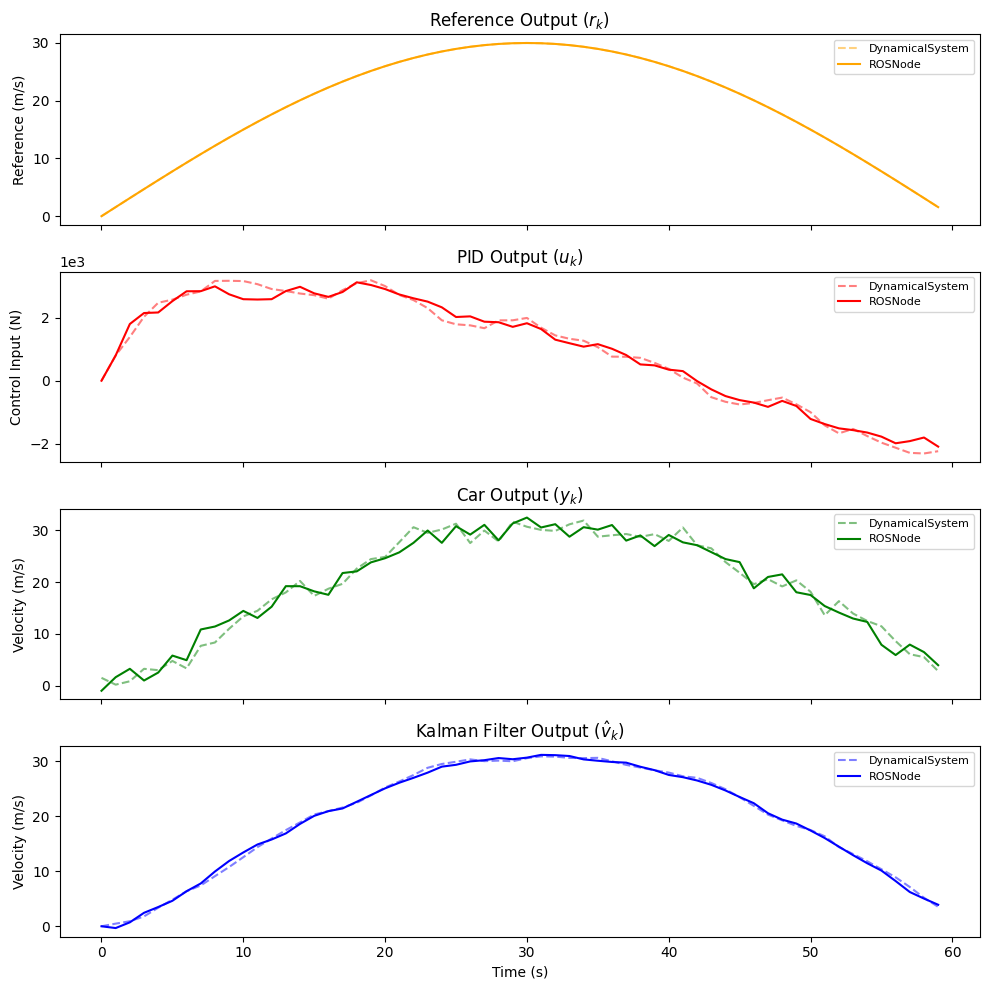

In [38]:
import os

os.makedirs("plots", exist_ok=True)

fig, axs = plt.subplots(4, 1, sharex=True, figsize=(10, 10))

for ax, ds, ros, color, ylabel, title in [
    (
        axs[0],
        ref_out,
        ref_node_out,
        "orange",
        "Reference (m/s)",
        "Reference Output ($r_k$)",
    ),
    (axs[1], ctrl_out, ctrl_node_out, "red", "Control Input (N)", "PID Output ($u_k$)"),
    (
        axs[2],
        plant_out,
        plant_node_out,
        "green",
        "Velocity (m/s)",
        "Car Output ($y_k$)",
    ),
    (
        axs[3],
        kf_out,
        kf_node_out,
        "blue",
        "Velocity (m/s)",
        "Kalman Filter Output ($\\hat{v}_k$)",
    ),
]:
    ax.plot(t_sim, ds, color=color, linestyle="--", alpha=0.5, label="DynamicalSystem")
    ax.plot(t_sim, ros, color=color, label="ROSNode")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
axs[1].ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
axs[3].set_xlabel("Time (s)")

plt.tight_layout()
plt.savefig("plots/cruise_control_async.png", dpi=200, bbox_inches="tight")
plt.show()

![DynamicalSystem versus ROSNode outputs for the cruise-control system.](plots/cruise_control_async.png)

The two runs use independent speedometer noise draws, so the plant and Kalman curves agree in shape but not sample for sample; the reference and the structure of the control signal should match.

#### Deploying to ROS2

[`write_ROSNode_to_rclpy()`](https://nehalsinghmangat.github.io/dynamicalnodes/api/rosnode.html#dynamicalnodes.rosnode.ROSNode.write_ROSNode_to_rclpy) generates a self-contained `rclpy` file for each node: a native `Node` subclass with explicit QoS profiles, subscription buffers, callbacks, publishers, and executor setup. No `dynamicalnodes` runtime is needed on the deployment machine beyond [`DynamicalSystem`](https://nehalsinghmangat.github.io/dynamicalnodes/api/dynamical_system.html#dynamicalnodes.dynamical_system.DynamicalSystem). Pass `node_name` here (not in the constructor), since it is a deployment detail and not a simulation one.

Parameters fall into three categories:

| Parameter | Purpose | Example |
|---|---|---|
| `static_params` | Baked in at generation time, never change | `dt`, `m`, `b`, `sigma`, `Fk`, `Bk`, `Hk`, `Qk`, `Rk` |
| `dynamic_params` | Declared on the ROS2 parameter server, tunable at runtime via `ros2 param set` | `KP`, `KI`, `KD` |
| `initial_inputs` | Cold-start value for a subscribed input, used only until the first message arrives; goes to `None` (not this value) if the publisher later stops | `xhatk=0.0` breaks the PID → KF startup ordering dependency |

Both the controller and the Kalman filter run on the same 10 Hz loop (`dt_ros = 0.1 s`), so each `stale_after` is a small multiple of that period, tight enough to reject genuinely old data and loose enough to tolerate scheduling jitter between processes:

- **PID controller** (`rk`, `xhatk`, `sync_mode="all"`): `stale_after=0.2 s`, 2× the control period. `sync_mode="all"` already forces both to be fresh *simultaneously*; the window additionally stops a slow-arriving input from being paired with one several cycles newer.
- **Kalman filter** (`uk`, `yk`, `sync_mode="any"`): `stale_after=0.15 s`, 1.5× the period. `plant_node` publishes `yk` almost immediately after the `uk` that produced it, so anything older means something is actually wrong (a stalled plant, dropped messages), not just jitter.

In [39]:
os.makedirs("./ros_nodes", exist_ok=True)

# The simulation uses dt=1.0 s; the ROS2 nodes fire at 10 Hz → dt=0.1 s.
ref_hz = 10  # must match timer_hz on the reference node below
dt_ros = 1.0 / ref_hz

# Recompute KF scalars for the deployment timestep.
Fk_ros = np.array([[1.0 - (b / m) * dt_ros]])
Bk_ros = np.array([[dt_ros / m]])
Qk_ros = Qk * (dt_ros / dt)  # process noise scales linearly with dt

ref_node.write_ROSNode_to_rclpy(
    "./ros_nodes/reference_node.py",
    node_name="reference",
    timer_hz=ref_hz,
    static_params={"A": A_ref, "omega": omega_ref},
)
pid_node.write_ROSNode_to_rclpy(
    "./ros_nodes/controller_node.py",
    node_name="controller",
    sync_mode="all",
    stale_after={"rk": 0.2, "xhatk": 0.2},
    initial_state=(0.0, 0.0),
    static_params={"dt": dt_ros},
    dynamic_params={"KP": KP, "KI": KI, "KD": KD},
    initial_inputs={"xhatk": 0.0},
)
plant_node.write_ROSNode_to_rclpy(
    "./ros_nodes/plant_node.py",
    node_name="plant",
    initial_state=0.0,
    static_params={"m": m, "b": b, "dt": dt_ros, "sigma": v_noise_std},
)
kf_node.write_ROSNode_to_rclpy(
    "./ros_nodes/kalman_node.py",
    node_name="kalman",
    sync_mode="any",  # update on /yk, predict on /uk
    stale_after={"uk": 0.15, "yk": 0.15},
    initial_state=(np.zeros(1), np.eye(1)),
    static_params={"Fk": Fk_ros, "Bk": Bk_ros, "Hk": Hk, "Qk": Qk_ros, "Rk": Rk},
)
print("Written: reference_node.py  controller_node.py  plant_node.py  kalman_node.py")

Written: reference_node.py  controller_node.py  plant_node.py  kalman_node.py


#### The Launch File

The cell below writes `ros_nodes/cruise_control.launch.py` next to the four generated node files; it resolves them relative to its own directory.

In [40]:
%%writefile ros_nodes/cruise_control.launch.py
#!/usr/bin/env python3
"""
Launch all four cruise-control nodes as separate processes.

Topic graph:
    reference  →  /rk    →  controller
    controller →  /uk    →  plant, kalman
    plant      →  /yk    →  kalman
    kalman     →  /xhatk →  controller

Startup ordering:
    Nodes may start in any order. The controller's initial_inputs={"xhatk": 0.0}
    provides a cold-start value for /xhatk so it does not stall waiting for the
    Kalman filter to produce its first estimate.

Run:
    ros2 launch ros_nodes/cruise_control.launch.py

Tune PID gains at runtime (no restart required):
    ros2 param set /controller KP 600.0
    ros2 param set /controller KI 25.0
    ros2 param set /controller KD 15.0

Inspect:
    ros2 topic echo /uk
    rqt_graph
"""

import os
from launch import LaunchDescription
from launch.actions import ExecuteProcess, TimerAction


def generate_launch_description() -> LaunchDescription:
    here = os.path.dirname(os.path.abspath(__file__))

    def py_node(script: str) -> ExecuteProcess:
        return ExecuteProcess(
            cmd=["python3", os.path.join(here, script)],
            output="screen",
        )

    return LaunchDescription(
        [
            py_node("reference_node.py"),
            py_node("controller_node.py"),
            py_node("plant_node.py"),
            py_node("kalman_node.py"),
            # Delay rqt_graph so all nodes have registered before it opens.
            TimerAction(
                period=2.0,
                actions=[ExecuteProcess(cmd=["rqt_graph"])],
            ),
        ]
    )

Overwriting ros_nodes/cruise_control.launch.py


#### Running the Live ROS2 Graph

**Terminal 1: launch all nodes.**

```bash
ros2 launch ros_nodes/cruise_control.launch.py
```

All four nodes start and stream their output to the terminal. After 2 seconds `rqt_graph` opens showing the live topic graph. If all four nodes are connected by the correct topics (`/rk`, `/uk`, `/yk`, `/xhatk`), everything is working. Here is `rqt_graph`, captured from an actual run of the four generated files, launched exactly as shown with no manual edits:

![Live rqt_graph of the cruise-control system: /reference publishes /rk into /controller, which publishes /uk into /plant and /kalman; /plant publishes /yk into /kalman; /kalman publishes /xhatk back into /controller, closing the loop.](rqt_graph_live.png)

**Terminal 2: visualize with PlotJuggler.**

```bash
source /opt/ros/jazzy/setup.bash
ros2 run plotjuggler plotjuggler --layout four_panel_cruise_control_layout.xml -p
```

`four_panel_cruise_control_layout.xml` lays out all four signals in a 2×2 grid and declares them as `selected_topics` on the `ROS2 Topic Subscriber` plugin, so `-p` starts streaming immediately, past the one-time "Start Streaming?" confirmation.

![PlotJuggler streaming live /rk, /uk, /yk, and /xhatk data from the full cruise-control system.](part3_plotjuggler_live.gif)

#### Tuning PID Gains Live

`KP`, `KI`, `KD` were declared as `dynamic_params`, so they are live ROS2 parameters on the running `controller` node. No restart is needed to change them:

```bash
ros2 param set /controller KP 600.0
ros2 param set /controller KI 25.0
ros2 param set /controller KD 15.0
ros2 param get /controller KP
```

Watch the effect in PlotJuggler (or with `ros2 topic echo /uk`). Because `fpid` has no integrator anti-windup or output saturation, this is also a good way to see a control loop go unstable: push `KI` or `KD` too high relative to the loop's `dt` and `/uk` will diverge instead of settle. Restore the original gains (`KP=500, KI=30, KD=10`) to recover.

#### You Don't Need the Launch File

The launch file is a convenience, not a requirement. [`write_ROSNode_to_rclpy()`](https://nehalsinghmangat.github.io/dynamicalnodes/api/rosnode.html#dynamicalnodes.rosnode.ROSNode.write_ROSNode_to_rclpy) produces ordinary standalone scripts, so, exactly as with the toy nodes in III-C, you can run each one directly:

```bash
python3 ros_nodes/reference_node.py &
python3 ros_nodes/controller_node.py &
python3 ros_nodes/plant_node.py &
python3 ros_nodes/kalman_node.py &
rqt_graph
```

Startup order does not matter, because `controller_node`'s `initial_inputs={"xhatk": 0.0}` gives it a cold-start value and every other subscription is happy to sit at `None` until its publisher comes up. Use `kill %1 %2 %3 %4` (or `pkill -f ros_nodes/`) to stop them.